# FASTA2GO — correlation matrices

Explores how the most frequent keyword terms (`words` and `phrases` from
`protein_keyword_terms`) co-occur across the 575,748 proteins, and how those
terms relate to amino-acid composition and to the numeric sequence features.

Matrices produced:

* **Phi coefficient** — Pearson correlation of binary presence vectors.
  `+1` = always together, `-1` = mutually exclusive, `0` = independent.
* **Jaccard** — `|A ∩ B| / |A ∪ B|`, pure overlap regardless of prevalence.
* **Amino acids vs terms** — point-biserial Pearson `r` between each amino
  acid percentage and term presence.
* **Sequence features vs terms** — point-biserial Pearson `r` between the
  15 numeric columns of `sequence_features` and term presence. Features
  are z-scored first so properties reported in different units (Da, %,
  bits, 0..1) sit on one common axis.
* **Sequence features** — Pearson `r` between the numeric columns of
  `sequence_features`.

Prerequisites: run `scripts/build_keyword_terms.py` first so
`protein_keyword_terms` exists in `proteins.duckdb`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "protein_database").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from protein_database.db import connect
from protein_database.schema import AMINO_ACIDS
from scripts.correlations import (
    FEATURE_COLUMNS,
    amino_acid_chunks,
    correlation_matrix_chunks,
    feature_chunks,
    feature_stats,
    feature_vs_terms,
    jaccard_matrix,
    phi_matrix,
    presence_matrix,
    sequence_feature_matrix,
    top_terms,
)

DB_PATH = Path(os.environ.get("FASTA2GO_DB", PROJECT_ROOT / "proteins.duckdb"))
TOP = 50

sns.set_theme(style="white", context="notebook")
plt.rcParams["figure.dpi"] = 110

conn = connect(DB_PATH)
print(f"database: {DB_PATH}")
print(f"terms per kind: {TOP}")

database: /home/orfeu/Documents/github/FASTA2GO/proteins.duckdb
terms per kind: 50


In [2]:
words = top_terms(conn, "words", TOP)
phrases = top_terms(conn, "phrases", TOP)

pd.DataFrame({
    "rank": range(1, TOP + 1),
    "word": words,
    "phrase": phrases,
}).head(15)

,rank,word,phrase
0,1,binding,plasma_membrane
1,2,cytoplasm,atp_binding
2,3,catalyzes,structural_constituent_ribosome
3,4,membrane,extracellular_region
4,5,biosynthetic,magnesium_ion_binding
5,6,cytosol,dna_binding
6,7,atp,rrna_binding
7,8,ion,zinc_ion_binding
8,9,cell,rna_binding
9,10,regulation,cytosolic_large_ribosomal_subunit


## 1. Word co-occurrence

In [3]:
word_presence = presence_matrix(conn, "words", words)
word_phi = phi_matrix(word_presence)
word_jaccard = jaccard_matrix(word_presence)

word_phi_df = pd.DataFrame(word_phi, index=words, columns=words)
word_phi_df.iloc[:6, :6].round(3)

,binding,cytoplasm,catalyzes,membrane,biosynthetic,cytosol
binding,1.000,0.122,0.053,-0.139,-0.015,0.125
cytoplasm,0.122,1.000,0.076,-0.133,0.081,-0.133
catalyzes,0.053,0.076,1.000,-0.131,0.434,0.165
membrane,-0.139,-0.133,-0.131,1.000,-0.078,-0.118
biosynthetic,-0.015,0.081,0.434,-0.078,1.000,0.111
cytosol,0.125,-0.133,0.165,-0.118,0.111,1.000


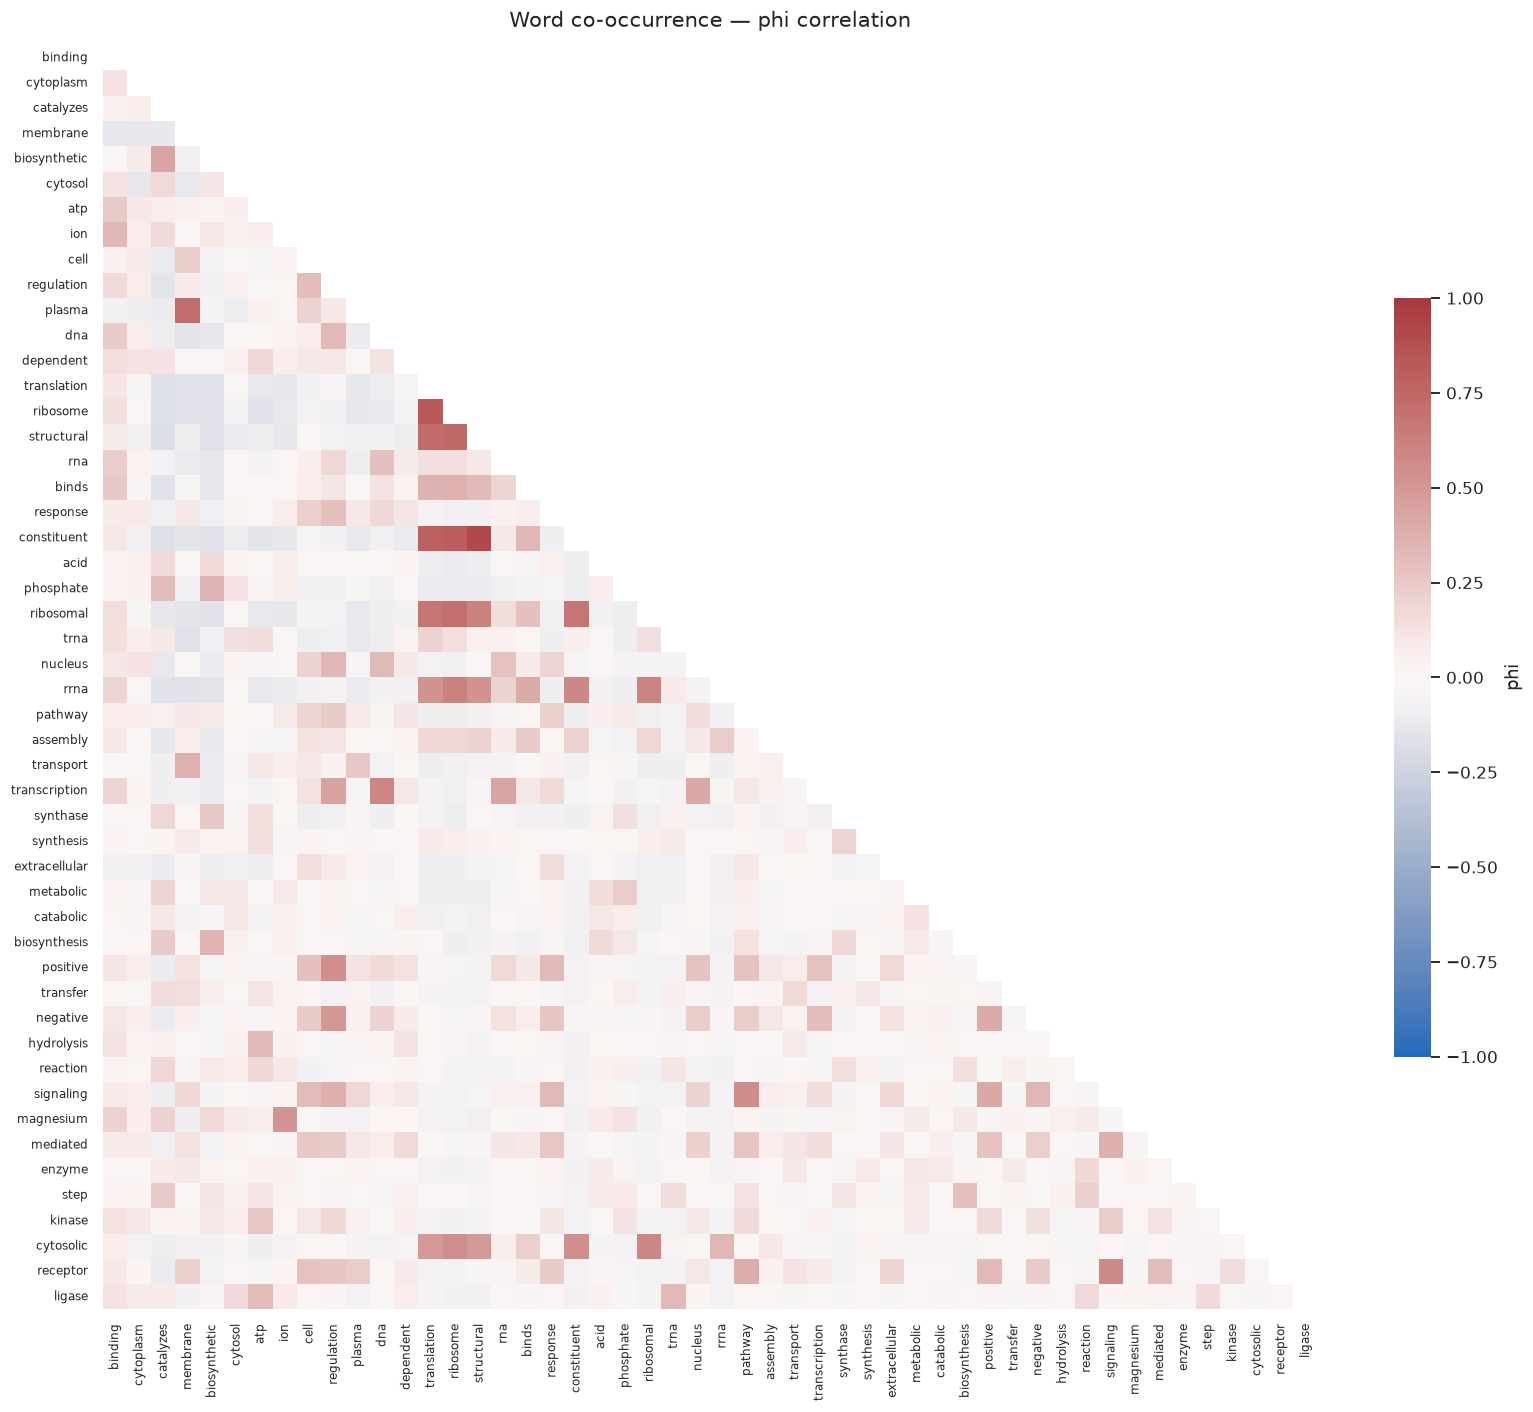

In [4]:
limit = float(np.abs(word_phi).max())
mask = np.triu(np.ones_like(word_phi, dtype=bool), k=0)

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    word_phi_df,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "phi"},
    ax=ax,
)
ax.set_title("Word co-occurrence — phi correlation", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [5]:
def pair_table(terms, matrix, n=12):
    """Long-format table of off-diagonal pairs, strongest positive first."""
    pairs = [
        (terms[i], terms[j], float(matrix[i, j]))
        for i in range(len(terms))
        for j in range(i + 1, len(terms))
    ]
    table = pd.DataFrame(pairs, columns=["term_a", "term_b", "value"])
    return table.sort_values("value", ascending=False).head(n).reset_index(drop=True)


pair_table(words, word_phi).round(3)

,term_a,term_b,value
0,structural,constituent,0.912
1,translation,ribosome,0.831
2,ribosome,constituent,0.809
3,translation,constituent,0.784
4,ribosome,structural,0.741
5,translation,structural,0.731
6,membrane,plasma,0.724
7,ribosome,ribosomal,0.718
8,translation,ribosomal,0.682
9,constituent,ribosomal,0.673


In [6]:
# Most mutually exclusive word pairs (tail of the same ranking).
pairs = [
    (words[i], words[j], float(word_phi[i, j]))
    for i in range(len(words))
    for j in range(i + 1, len(words))
]
pd.DataFrame(pairs, columns=["term_a", "term_b", "phi"]).nsmallest(8, "phi").round(3)

,term_a,term_b,phi
109,catalyzes,structural,-0.185
113,catalyzes,constituent,-0.174
108,catalyzes,ribosome,-0.170
107,catalyzes,translation,-0.168
153,membrane,translation,-0.163
198,biosynthetic,translation,-0.163
163,membrane,trna,-0.159
200,biosynthetic,structural,-0.159


## 2. Phrase co-occurrence

In [7]:
phrase_presence = presence_matrix(conn, "phrases", phrases)
phrase_phi = phi_matrix(phrase_presence)
phrase_jaccard = jaccard_matrix(phrase_presence)

phrase_phi_df = pd.DataFrame(phrase_phi, index=phrases, columns=phrases)
phrase_phi_df.iloc[:6, :6].round(3)

,plasma_membrane,atp_binding,structural_constituent_ribosome,extracellular_region,magnesium_ion_binding,dna_binding
plasma_membrane,1.000,0.028,-0.117,-0.020,-0.069,-0.070
atp_binding,0.028,1.000,-0.116,-0.086,0.079,-0.007
structural_constituent_ribosome,-0.117,-0.116,1.000,-0.077,-0.070,-0.066
extracellular_region,-0.020,-0.086,-0.077,1.000,-0.030,-0.048
magnesium_ion_binding,-0.069,0.079,-0.070,-0.030,1.000,-0.002
dna_binding,-0.070,-0.007,-0.066,-0.048,-0.002,1.000


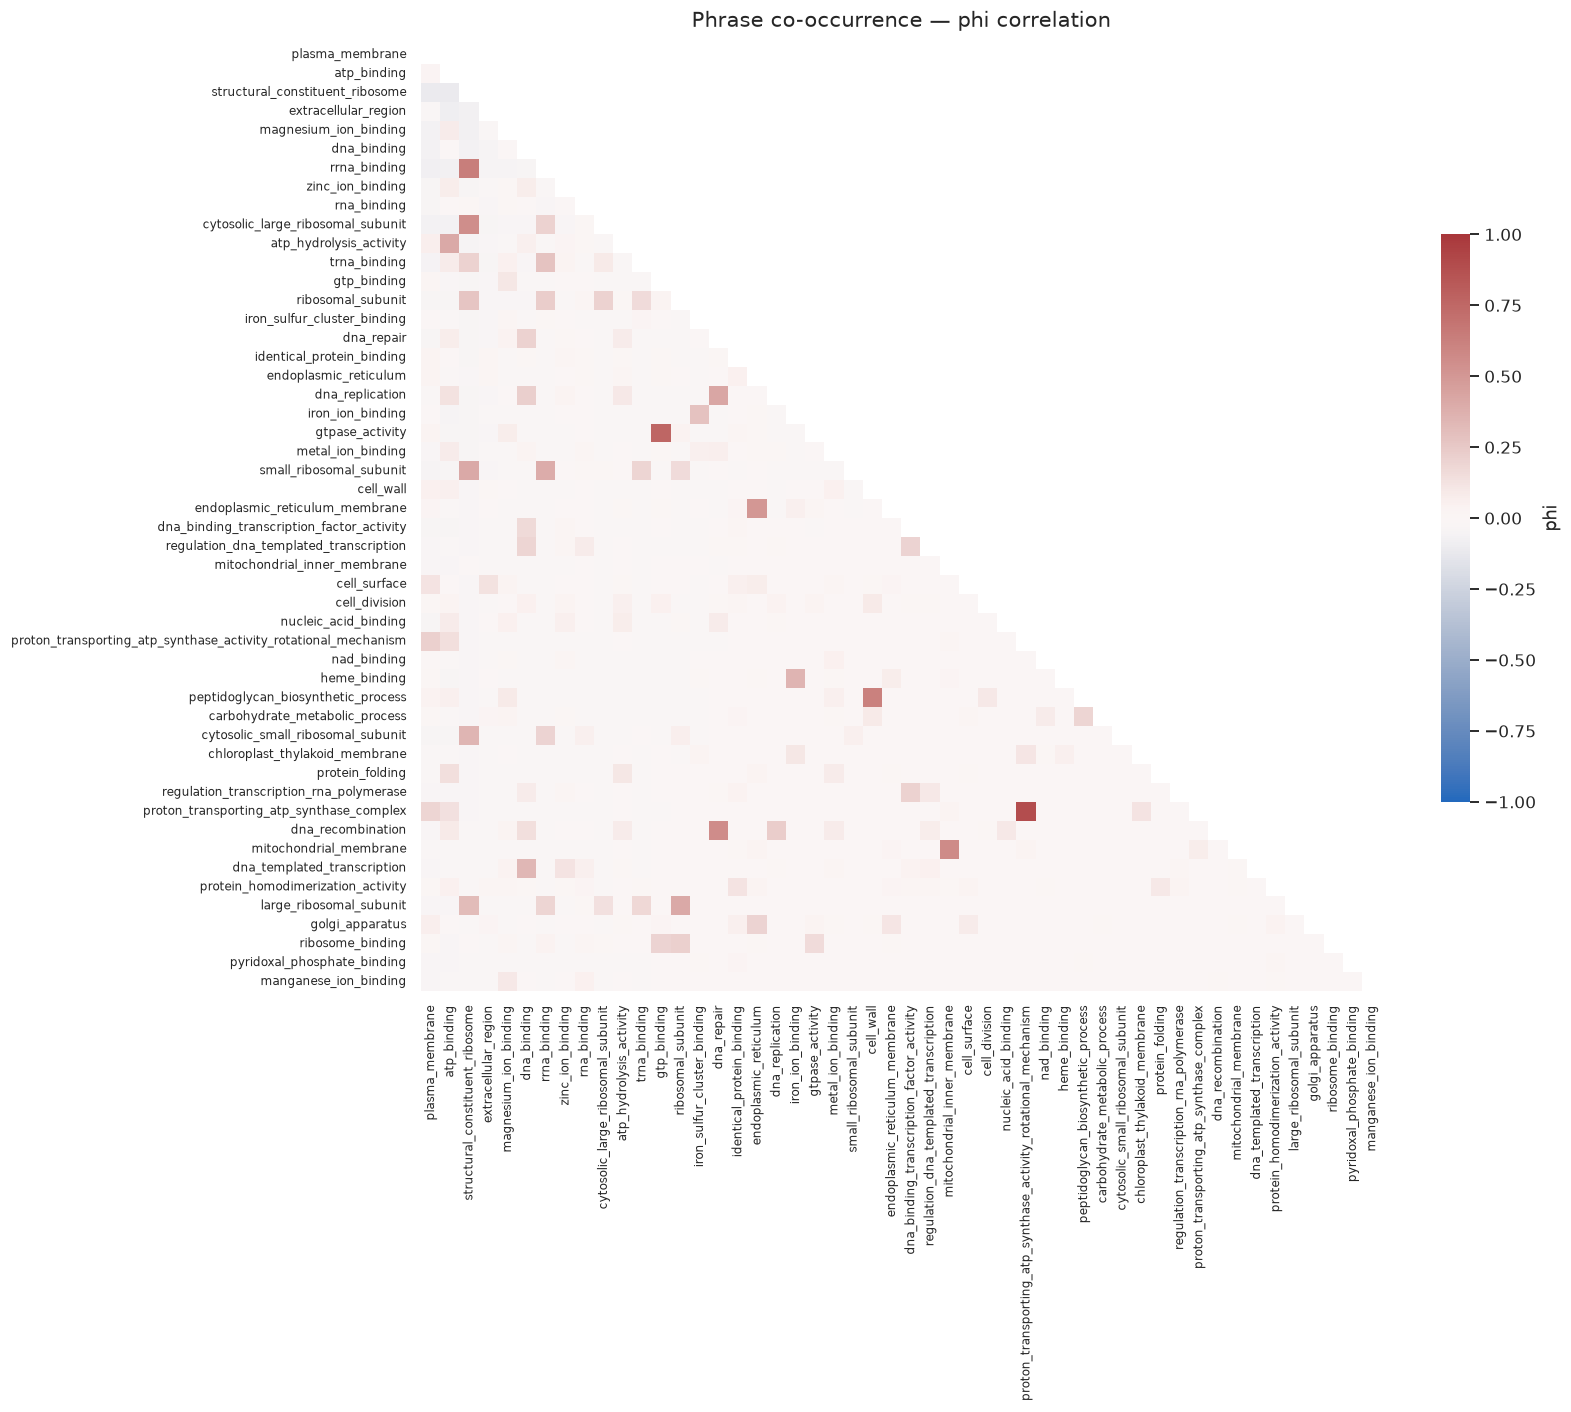

In [8]:
limit = float(np.abs(phrase_phi).max())
mask = np.triu(np.ones_like(phrase_phi, dtype=bool), k=0)

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    phrase_phi_df,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "phi"},
    ax=ax,
)
ax.set_title("Phrase co-occurrence — phi correlation", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [9]:
pair_table(phrases, phrase_phi).round(3)

,term_a,term_b,value
0,proton_transporting_atp_synthase_activity_rota...,proton_transporting_atp_synthase_complex,0.886
1,gtp_binding,gtpase_activity,0.760
2,structural_constituent_ribosome,rrna_binding,0.635
3,cell_wall,peptidoglycan_biosynthetic_process,0.624
4,mitochondrial_inner_membrane,mitochondrial_membrane,0.568
5,dna_repair,dna_recombination,0.556
6,structural_constituent_ribosome,cytosolic_large_ribosomal_subunit,0.550
7,endoplasmic_reticulum,endoplasmic_reticulum_membrane,0.506
8,dna_repair,dna_replication,0.422
9,atp_binding,atp_hydrolysis_activity,0.410


In [10]:
# Jaccard is prevalence-insensitive, so rare concepts show their overlap.
phrase_jaccard_df = pd.DataFrame(phrase_jaccard, index=phrases, columns=phrases)
pair_table(phrases, phrase_jaccard).round(3)

,term_a,term_b,value
0,proton_transporting_atp_synthase_activity_rota...,proton_transporting_atp_synthase_complex,0.792
1,gtp_binding,gtpase_activity,0.609
2,cell_wall,peptidoglycan_biosynthetic_process,0.451
3,structural_constituent_ribosome,rrna_binding,0.450
4,mitochondrial_inner_membrane,mitochondrial_membrane,0.395
5,dna_repair,dna_recombination,0.366
6,endoplasmic_reticulum,endoplasmic_reticulum_membrane,0.344
7,structural_constituent_ribosome,cytosolic_large_ribosomal_subunit,0.323
8,dna_repair,dna_replication,0.276
9,ribosomal_subunit,large_ribosomal_subunit,0.239


## 3. Amino-acid composition vs terms

Each cell is the Pearson correlation (point-biserial) between one amino
acid's percentage in the protein and whether the term is present. Percentages
are compositional (they sum to 100 per protein), so the 20 rows are not
statistically independent.

In [11]:
amino_acids = list(AMINO_ACIDS.values())

aa_words = correlation_matrix_chunks(
    amino_acid_chunks(conn, "words", words, batch_size=25_000)
)
aa_phrases = correlation_matrix_chunks(
    amino_acid_chunks(conn, "phrases", phrases, batch_size=25_000)
)

aa_words_df = pd.DataFrame(aa_words, index=amino_acids, columns=words)
aa_phrases_df = pd.DataFrame(aa_phrases, index=amino_acids, columns=phrases)
aa_words_df.iloc[:, :6].round(3)

,binding,cytoplasm,catalyzes,membrane,biosynthetic,cytosol
alanine,0.021,0.006,0.128,-0.034,0.133,0.042
arginine,0.103,-0.010,-0.072,-0.159,-0.049,-0.027
asparagine,-0.028,-0.035,-0.063,-0.015,-0.073,-0.019
aspartic_acid,0.115,0.118,0.103,-0.237,0.074,0.134
cysteine,-0.074,-0.040,-0.059,-0.002,-0.054,-0.067
glutamine,0.042,0.033,-0.096,-0.022,-0.083,0.026
glutamic_acid,0.163,0.122,0.003,-0.246,-0.011,0.141
glycine,0.032,0.009,0.136,-0.032,0.106,0.019
histidine,0.040,0.038,0.070,-0.098,0.060,0.008
isoleucine,-0.039,-0.007,0.064,0.102,0.057,-0.004


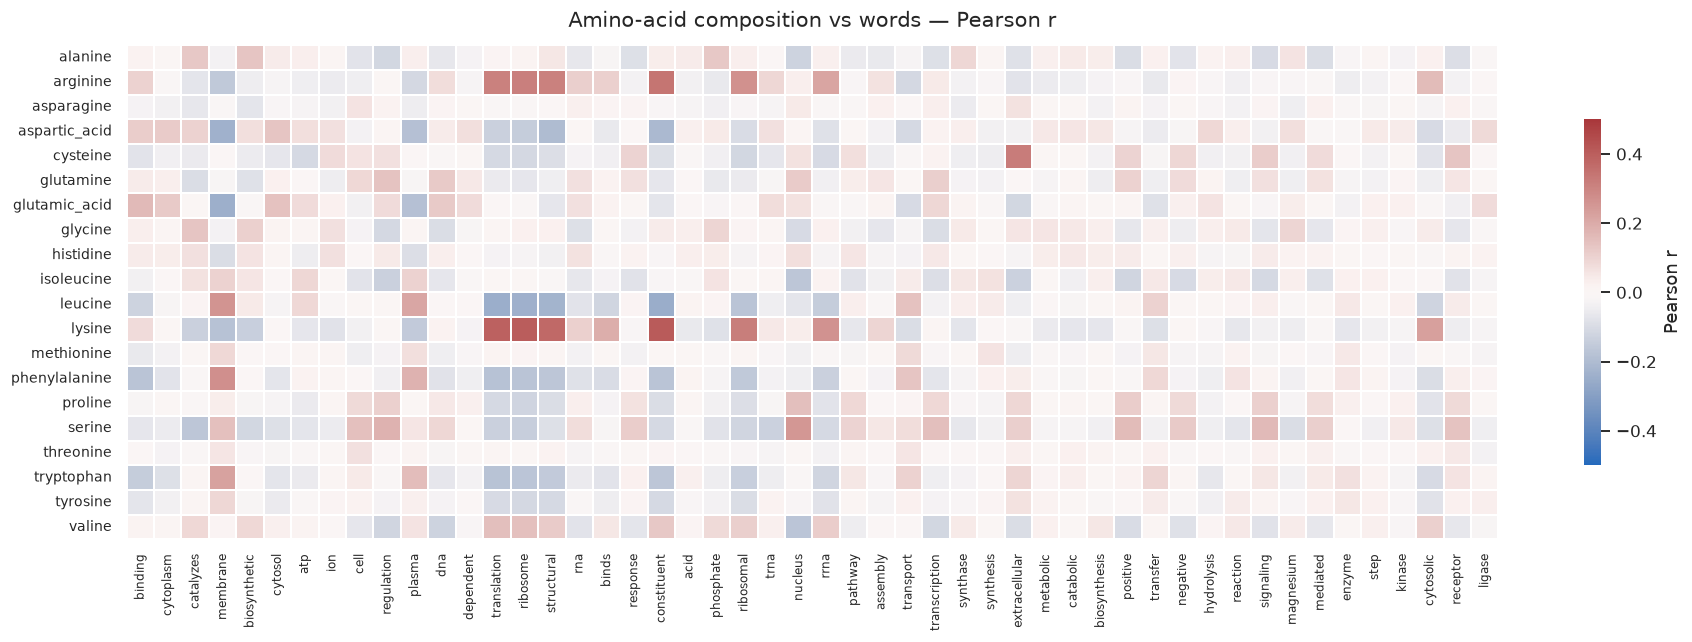

In [12]:
fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    aa_words_df,
    cmap="vlag",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Amino-acid composition vs words — Pearson r", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

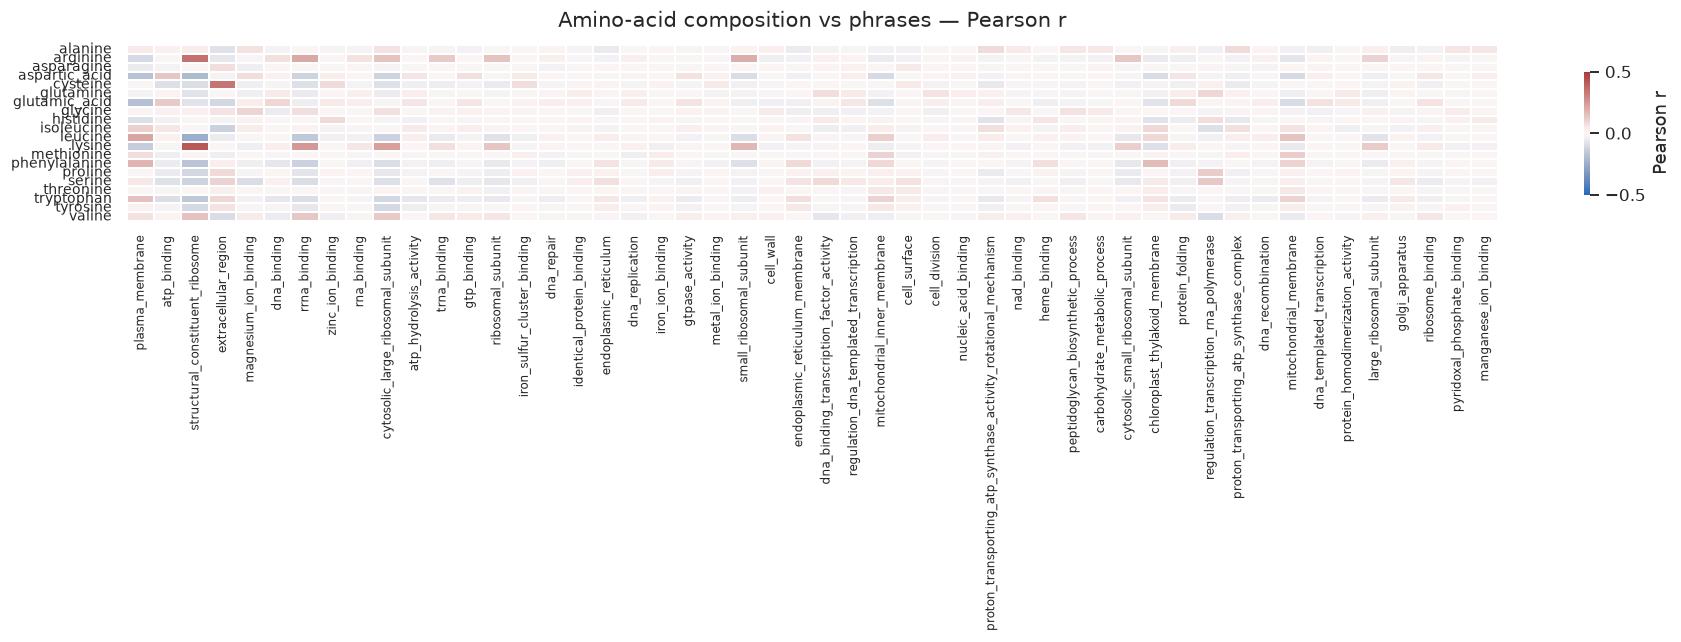

In [13]:
fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    aa_phrases_df,
    cmap="vlag",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Amino-acid composition vs phrases — Pearson r", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

In [14]:
# Strongest absolute associations, regardless of sign.
flat = [
    (amino_acids[i], phrases[j], float(aa_phrases[i, j]))
    for i in range(len(amino_acids))
    for j in range(len(phrases))
]
strongest = pd.DataFrame(flat, columns=["amino_acid", "phrase", "r"])
strongest["abs_r"] = strongest["r"].abs()
strongest.sort_values("abs_r", ascending=False).head(15).drop(columns="abs_r").round(3)

,amino_acid,phrase,r
552,lysine,structural_constituent_ribosome,0.418
52,arginine,structural_constituent_ribosome,0.353
203,cysteine,extracellular_region,0.338
502,leucine,structural_constituent_ribosome,-0.248
556,lysine,rrna_binding,0.247
559,lysine,cytosolic_large_ribosomal_subunit,0.229
500,leucine,plasma_membrane,0.212
56,arginine,rrna_binding,0.211
152,aspartic_acid,structural_constituent_ribosome,-0.203
72,arginine,small_ribosomal_subunit,0.194


## 4. Sequence features

Pearson correlation across the 15 numeric columns of `sequence_features`
(physicochemical properties plus complexity measures). The matrix is built
by `scripts/correlations.py`, so this chart and the exported
`exports/correlations/plots/sequence_features_correlation.png` share the
same code. Values are signed: `+1` = the features grow together, `-1` =
one grows as the other shrinks, `0` = no linear association.


In [15]:
feature_matrix = sequence_feature_matrix(conn, batch_size=25_000)
sequence_features_df = pd.DataFrame(
    feature_matrix, index=FEATURE_COLUMNS, columns=FEATURE_COLUMNS
)
sequence_features_df.round(3)

,molecular_weight,isoelectric_point,gravy_index,instability_index,aliphatic_index,aromaticity,charge_positive_percentage,charge_negative_percentage,hydrophobic_percentage,polar_percentage,charged_percentage,sulfur_percentage,aromatic_percentage,sequence_entropy,amino_acid_diversity
molecular_weight,1.000,-0.151,-0.075,0.083,-0.069,0.036,-0.118,0.085,-0.092,0.144,-0.034,-0.101,0.036,0.300,0.303
isoelectric_point,-0.151,1.000,-0.074,0.099,-0.041,0.026,0.549,-0.593,-0.052,0.030,0.033,0.035,0.026,-0.182,-0.152
gravy_index,-0.075,-0.074,1.000,-0.392,0.795,0.244,-0.648,-0.466,0.872,-0.217,-0.774,0.109,0.244,-0.070,0.012
instability_index,0.083,0.099,-0.392,1.000,-0.343,-0.081,0.246,0.047,-0.393,0.246,0.212,0.133,-0.081,-0.044,-0.007
aliphatic_index,-0.069,-0.041,0.795,-0.343,1.000,0.009,-0.371,-0.203,0.818,-0.374,-0.403,-0.222,0.009,-0.054,0.038
aromaticity,0.036,0.026,0.244,-0.081,0.009,1.000,-0.248,-0.246,0.358,0.042,-0.339,0.070,1.000,0.194,0.081
charge_positive_percentage,-0.118,0.549,-0.648,0.246,-0.371,-0.248,1.000,0.057,-0.484,-0.159,0.777,-0.050,-0.248,-0.129,-0.165
charge_negative_percentage,0.085,-0.593,-0.466,0.047,-0.203,-0.246,0.057,1.000,-0.321,-0.224,0.673,-0.193,-0.246,0.174,0.118
hydrophobic_percentage,-0.092,-0.052,0.872,-0.393,0.818,0.358,-0.484,-0.321,1.000,-0.462,-0.561,-0.110,0.358,-0.022,0.048
polar_percentage,0.144,0.030,-0.217,0.246,-0.374,0.042,-0.159,-0.224,-0.462,1.000,-0.259,0.323,0.042,0.104,0.028


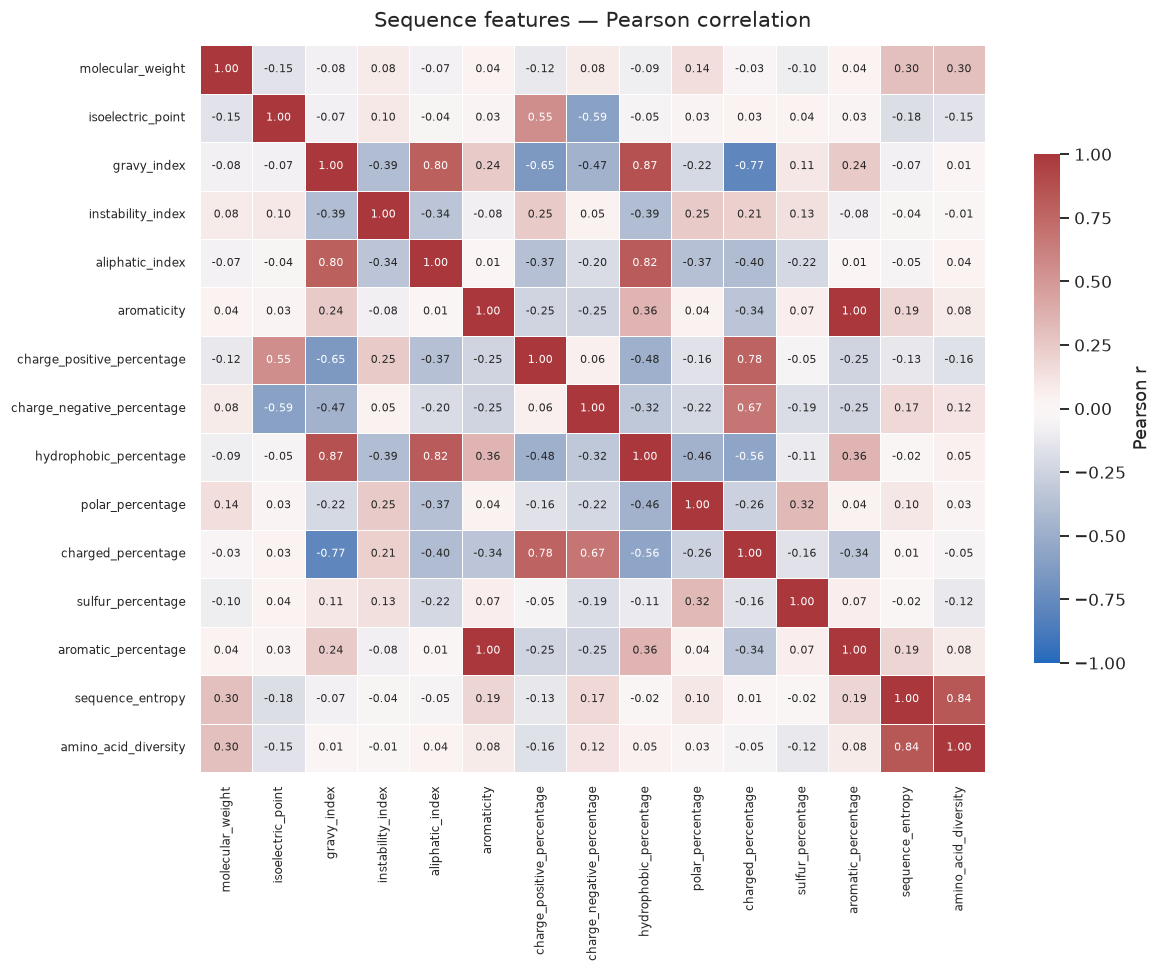

In [16]:
off_diagonal = ~np.eye(len(FEATURE_COLUMNS), dtype=bool)
limit = float(np.abs(feature_matrix[off_diagonal]).max())

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    sequence_features_df,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.4,
    linecolor="white",
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Sequence features — Pearson correlation", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [17]:
# Strongest off-diagonal associations, regardless of sign.
pairs = [
    (FEATURE_COLUMNS[i], FEATURE_COLUMNS[j], float(feature_matrix[i, j]))
    for i in range(len(FEATURE_COLUMNS))
    for j in range(i + 1, len(FEATURE_COLUMNS))
]
strongest_features = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "r"])
strongest_features["abs_r"] = strongest_features["r"].abs()
strongest_features.sort_values("abs_r", ascending=False).head(12).drop(
    columns="abs_r"
).round(3)

,feature_a,feature_b,r
66,aromaticity,aromatic_percentage,1.000
32,gravy_index,hydrophobic_percentage,0.872
104,sequence_entropy,amino_acid_diversity,0.837
53,aliphatic_index,hydrophobic_percentage,0.818
28,gravy_index,aliphatic_index,0.795
72,charge_positive_percentage,charged_percentage,0.777
34,gravy_index,charged_percentage,-0.774
79,charge_negative_percentage,charged_percentage,0.673
30,gravy_index,charge_positive_percentage,-0.648
19,isoelectric_point,charge_negative_percentage,-0.593


## 5. Sequence features vs terms (scaled)

Each cell is the Pearson correlation (point-biserial) between one numeric
`sequence_features` column and whether the term is present. The 15 features
live on wildly different scales — molecular weight in Da, aromaticity in
0..1, percentages in 0..100 — so they are standardized (z-scored) first:
each column becomes `(value - mean) / std`, centred on 0 with unit spread,
which puts every property on one common axis.

Pearson is affine-invariant, so standardizing **cannot** change `r`; the
cell after the heatmaps verifies this on the real database (the two matrices
agree to floating-point noise). What the scaling buys is comparable feature
magnitudes and a single colour scale, not a different coefficient.

In [18]:
# The standardization itself: every feature on the same footing.
feature_mean, feature_std = feature_stats(conn)
feature_scaling = pd.DataFrame(
    {"mean": feature_mean, "std": feature_std}, index=FEATURE_COLUMNS
)
feature_scaling.round(3)

,mean,std
molecular_weight,40345.371,38402.661
isoelectric_point,6.998,1.949
gravy_index,-0.214,0.413
instability_index,39.178,13.179
aliphatic_index,89.871,17.303
aromaticity,0.078,0.032
charge_positive_percentage,14.169,4.611
charge_negative_percentage,11.885,3.927
hydrophobic_percentage,41.513,6.373
polar_percentage,20.717,5.245


In [19]:
feature_words = feature_vs_terms(conn, "words", words, batch_size=25_000)
feature_phrases = feature_vs_terms(conn, "phrases", phrases, batch_size=25_000)

feature_words_df = pd.DataFrame(
    feature_words, index=FEATURE_COLUMNS, columns=words
)
feature_phrases_df = pd.DataFrame(
    feature_phrases, index=FEATURE_COLUMNS, columns=phrases
)
feature_words_df.iloc[:, :8].round(3)

,binding,cytoplasm,catalyzes,membrane,biosynthetic,cytosol,atp,ion
molecular_weight,0.156,0.048,0.066,0.117,0.016,0.066,0.146,0.092
isoelectric_point,-0.025,-0.122,-0.189,0.110,-0.148,-0.174,-0.166,-0.121
gravy_index,-0.191,-0.067,0.131,0.352,0.143,-0.050,0.079,0.041
instability_index,0.007,-0.008,-0.153,-0.009,-0.124,-0.036,-0.067,-0.038
aliphatic_index,-0.100,-0.013,0.111,0.241,0.130,-0.000,0.132,-0.010
aromaticity,-0.195,-0.095,0.003,0.291,-0.014,-0.096,-0.010,0.015
charge_positive_percentage,0.140,0.010,-0.127,-0.270,-0.118,-0.020,-0.095,-0.075
charge_negative_percentage,0.179,0.151,0.057,-0.304,0.032,0.174,0.097,0.054
hydrophobic_percentage,-0.169,-0.060,0.142,0.318,0.147,-0.028,0.105,0.007
polar_percentage,-0.061,-0.054,-0.173,0.080,-0.147,-0.076,-0.097,-0.027


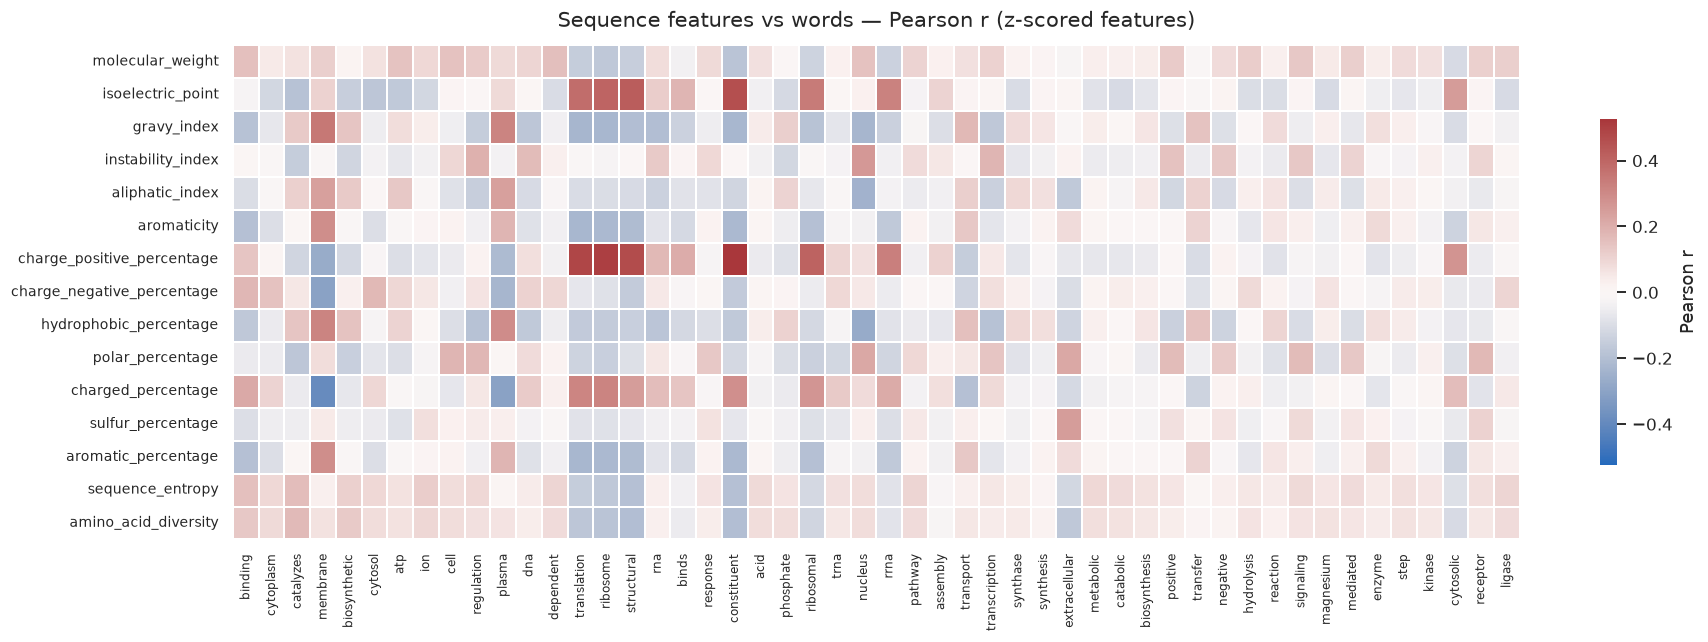

In [20]:
limit = float(np.abs(feature_words).max())

fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    feature_words_df,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title(
    "Sequence features vs words — Pearson r (z-scored features)",
    fontsize=14,
    pad=12,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

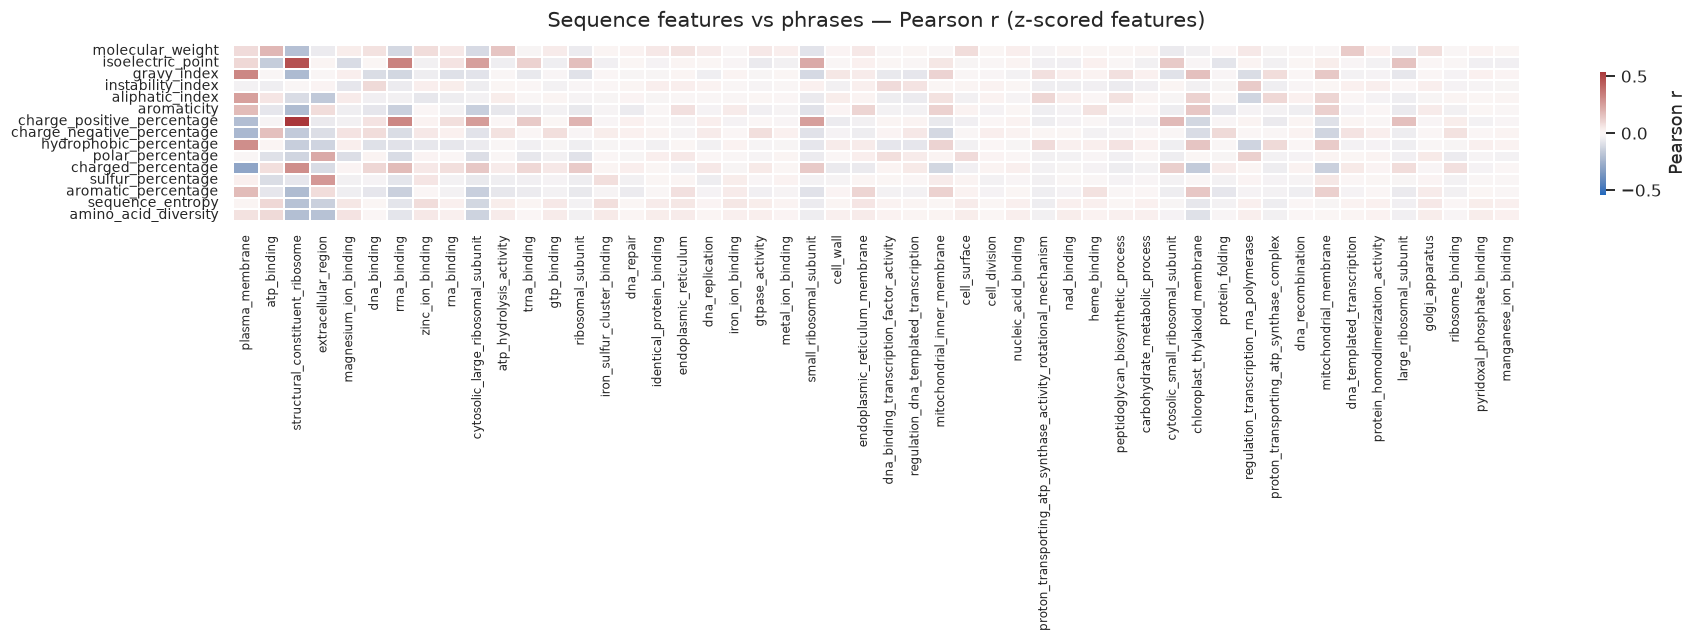

In [21]:
limit = float(np.abs(feature_phrases).max())

fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    feature_phrases_df,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title(
    "Sequence features vs phrases — Pearson r (z-scored features)",
    fontsize=14,
    pad=12,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

In [22]:
# z-scoring is affine: the coefficients are identical to the raw ones.
feature_words_raw = feature_vs_terms(
    conn, "words", words, batch_size=25_000, scaled=False
)
print(
    "max |r(z-scored) - r(raw)| = "
    f"{np.abs(feature_words_raw - feature_words).max():.2e}"
)

pairs = [
    (
        FEATURE_COLUMNS[i],
        words[j],
        float(feature_words[i, j]),
        float(feature_words_raw[i, j]),
    )
    for i in range(len(FEATURE_COLUMNS))
    for j in range(len(words))
]
strongest_feature_words = pd.DataFrame(
    pairs, columns=["feature", "word", "r_scaled", "r_raw"]
)
strongest_feature_words["abs_r"] = strongest_feature_words["r_scaled"].abs()
strongest_feature_words["delta"] = (
    strongest_feature_words["r_scaled"] - strongest_feature_words["r_raw"]
)
strongest_feature_words.sort_values("abs_r", ascending=False).head(15).drop(
    columns="abs_r"
).round(3)

max |r(z-scored) - r(raw)| = 2.95e-12


,feature,word,r_scaled,r_raw,delta
319,charge_positive_percentage,constituent,0.525,0.525,0.0
314,charge_positive_percentage,ribosome,0.503,0.503,0.0
313,charge_positive_percentage,translation,0.487,0.487,0.0
315,charge_positive_percentage,structural,0.471,0.471,0.0
69,isoelectric_point,constituent,0.460,0.460,0.0
65,isoelectric_point,structural,0.423,0.423,0.0
322,charge_positive_percentage,ribosomal,0.407,0.407,0.0
64,isoelectric_point,ribosome,0.403,0.403,0.0
503,charged_percentage,membrane,-0.392,-0.392,0.0
63,isoelectric_point,translation,0.380,0.380,0.0


In [23]:
# How much the features and the words have in common: shared variance r^2.
by_word = pd.DataFrame(
    {
        "best_feature": [
            FEATURE_COLUMNS[int(np.argmax(np.abs(feature_words[:, j])))]
            for j in range(len(words))
        ],
        "max_abs_r": np.abs(feature_words).max(axis=0),
    },
    index=words,
)
by_word["shared_variance"] = by_word["max_abs_r"] ** 2
display(by_word.sort_values("max_abs_r", ascending=False).head(15).round(3))

by_feature = pd.DataFrame(
    {
        "mean_abs_r": np.abs(feature_words).mean(axis=1),
        "mean_shared_variance": (feature_words**2).mean(axis=1),
        "max_abs_r": np.abs(feature_words).max(axis=1),
    },
    index=FEATURE_COLUMNS,
).sort_values("mean_shared_variance", ascending=False)
by_feature.round(3)

,best_feature,max_abs_r,shared_variance
constituent,charge_positive_percentage,0.525,0.276
ribosome,charge_positive_percentage,0.503,0.253
translation,charge_positive_percentage,0.487,0.237
structural,charge_positive_percentage,0.471,0.222
ribosomal,charge_positive_percentage,0.407,0.165
membrane,charged_percentage,0.392,0.153
rrna,charge_positive_percentage,0.332,0.110
plasma,gravy_index,0.317,0.101
cytosolic,charge_positive_percentage,0.271,0.074
nucleus,hydrophobic_percentage,0.271,0.073


,mean_abs_r,mean_shared_variance,max_abs_r
charge_positive_percentage,0.125,0.035,0.525
isoelectric_point,0.111,0.027,0.460
charged_percentage,0.104,0.020,0.392
gravy_index,0.109,0.018,0.352
hydrophobic_percentage,0.108,0.017,0.318
polar_percentage,0.093,0.012,0.221
aromaticity,0.077,0.011,0.291
aromatic_percentage,0.077,0.011,0.291
aliphatic_index,0.085,0.011,0.246
molecular_weight,0.088,0.010,0.185


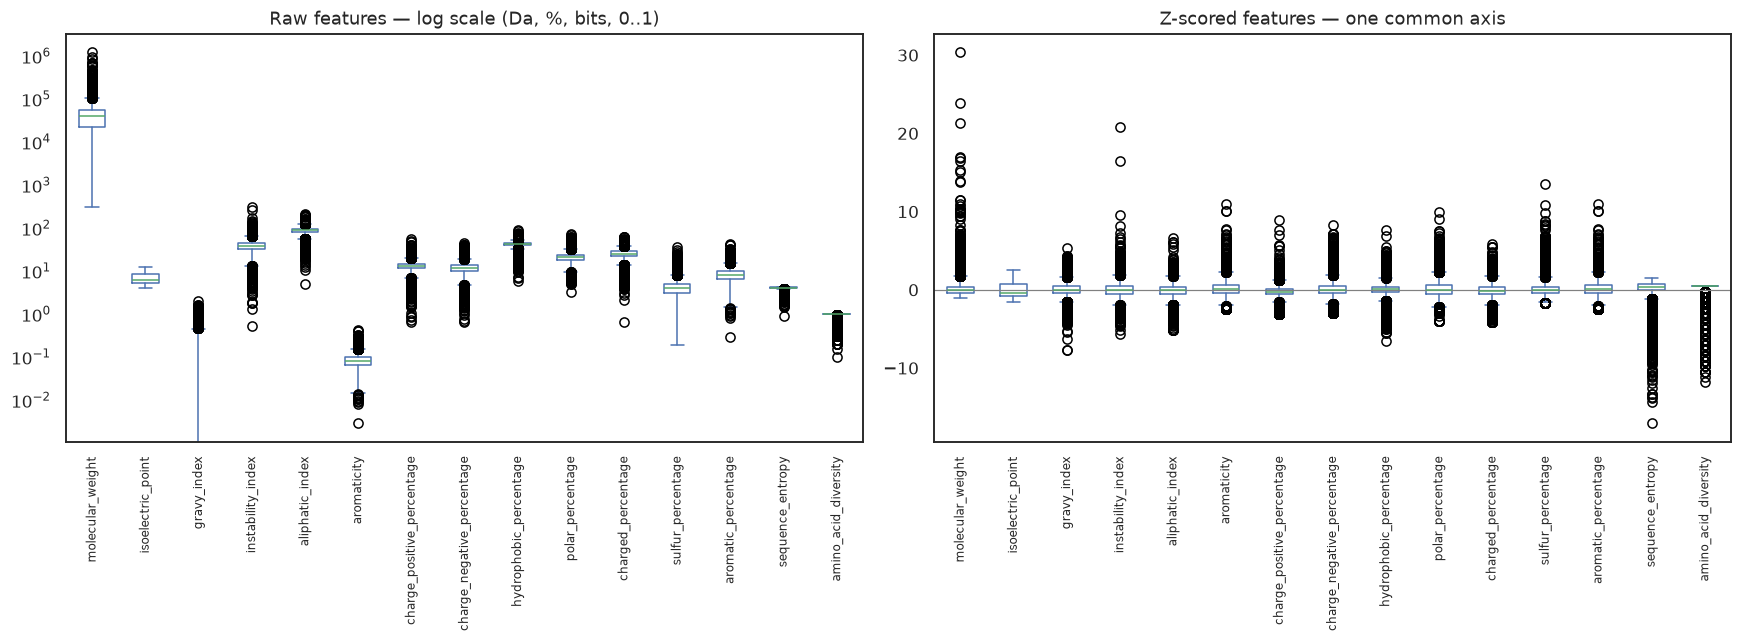

In [24]:
# The point of scaling: one common axis for properties in different units.
sample = pd.DataFrame(next(feature_chunks(conn, 20_000)), columns=FEATURE_COLUMNS)
scaled_sample = (sample - feature_mean) / feature_std

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sample.plot(kind="box", ax=axes[0], logy=True, legend=False)
axes[0].set_title("Raw features — log scale (Da, %, bits, 0..1)", fontsize=12)
scaled_sample.plot(kind="box", ax=axes[1], legend=False)
axes[1].set_title("Z-scored features — one common axis", fontsize=12)
for ax in axes:
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
axes[1].axhline(0, color="grey", linewidth=0.8)
plt.tight_layout()
plt.show()

## 6. Optional export

Flip `SAVE_FIGURES` to write the current figures to
`exports/correlations/plots/notebook/` as PNGs.

In [25]:
SAVE_FIGURES = False
OUT_DIR = PROJECT_ROOT / "exports" / "correlations" / "plots" / "notebook"

if SAVE_FIGURES:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for number, figure in enumerate(plt.get_fignums(), start=1):
        plt.figure(figure).savefig(OUT_DIR / f"figure_{number:02d}.png", dpi=200)
    print(f"saved {len(plt.get_fignums())} figures to {OUT_DIR}")
else:
    print("export disabled (set SAVE_FIGURES = True)")

export disabled (set SAVE_FIGURES = True)


In [26]:
conn.close()